In [12]:
%load_ext autoreload
%autoreload 2

import xr_ccew as tw
import xarray as xr
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from scipy.signal import hilbert
from src.loading import (
    load_noaa_daily_olr,
    load_wave_filtered_olr,
    load_noaa_daily_olr_spectral_power
)
from src.spectral_power import (
    spectral_power_pipeline,
    add_matsuno_curves
)


from src.wave_profiles import BOX_PROFILES as profiles
from src.plotting import save_figure

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Spacetime Spectral Power

In [7]:
spectral_power = load_noaa_daily_olr_spectral_power()

Spectral power not cached, computing now...


Saving /home1/pedro/Projects/observed_equivalent_depth_range/figures/NOAA_Daily_OLR_Normed_Power.pdf as PDF ...


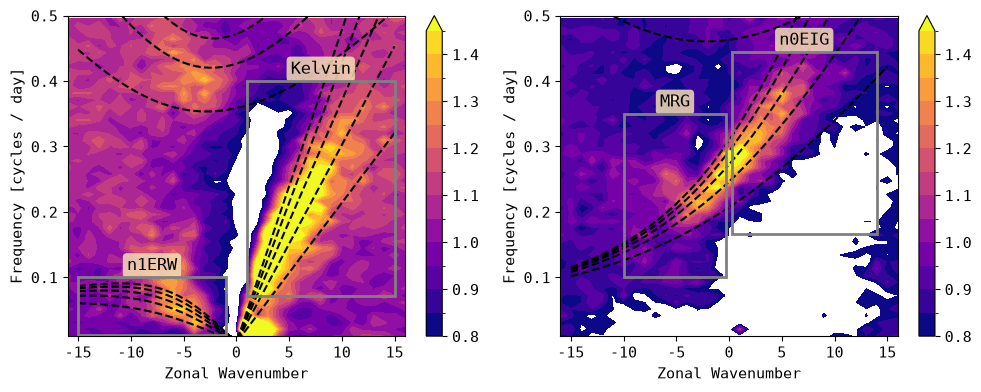

In [15]:
def wk99_plot(ax, power):
    levels = np.arange(0.8, 1.5, 0.05)
    power.plot.contourf(
        ax=ax,
        y='frequency',
        cmap=plt.cm.plasma,
        vmin=min(levels),
        vmax=max(levels),
        levels=len(levels),
        extend='max',
        cbar_kwargs={'label': None}
    )

power_sym = spectral_power['symmetric']
power_asym = spectral_power['antisymmetric']
bg = tw.background_spectrum(0.5*(power_sym+power_asym))

fig, axs = plt.subplots(ncols=2, figsize=(10, 4))

ax = axs[0]
wk99_plot(ax, power_sym/bg)
add_matsuno_curves(ax, 'symmetric', he_list=[10, 20, 30, 40, 50])

ax = axs[1]
wk99_plot(ax, power_asym/bg)
add_matsuno_curves(ax, 'antisymmetric', he_list=[10, 20, 30, 40, 50])

for wave, profile in profiles.items():
    ax = axs[0 if profile.symmetry == "symmetric" else 1]

    ax.add_patch(
        Rectangle(
            (profile.k_min, profile.frequency_min),
            profile.k_max - profile.k_min,
            profile.frequency_max - profile.frequency_min,
            fill=False,
            edgecolor="grey",
            linewidth=2,
            zorder=5,
        )
    )
    ax.text(
        (profile.k_min + profile.k_max) / 2,
        profile.frequency_max + 0.005,
        wave,
        ha="center",
        va="bottom",
        fontsize=12,
        bbox=dict(
            boxstyle="round,pad=0.25",
            facecolor="wheat",
            edgecolor="none",
            alpha=0.85,
        ),

    )

for ax in axs:     
    ax.set_ylim(0.01, 0.5)
    ax.set_xlim(-16, 16)
    ax.set_xlabel('Zonal Wavenumber')
    ax.set_ylabel('Frequency [cycles / day]')

fig.tight_layout(pad=1)
save_figure(fig, 'NOAA_Daily_OLR_Normed_Power.pdf')


                             h_m  c_m_s
Fit                                    
Equal weights              14.85  12.07
Excess-prominence weighted 17.56  13.12


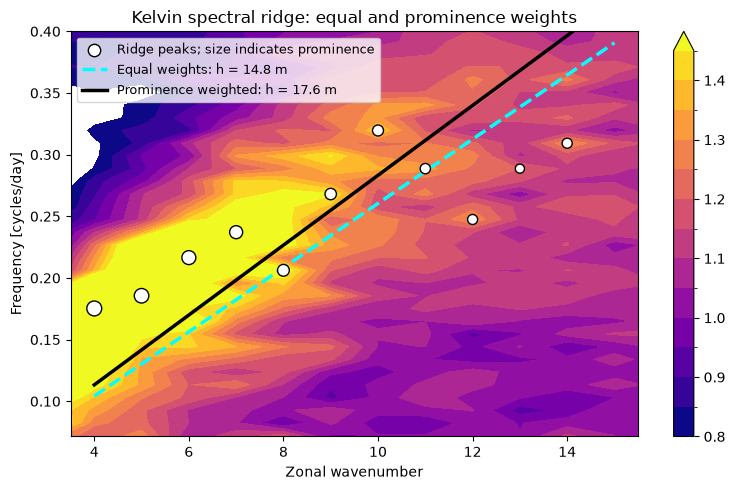

In [65]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from xr_ccew.matsuno import kelvin_frequency

# Selection settings: your Kelvin box, excluding K < 4 to reduce MJO overlap.
p = profiles["Kelvin"]
k_min, k_max = max(4, p.k_min), p.k_max
f_min, f_max = p.frequency_min, p.frequency_max
min_ratio = 1.10  # Selection cutoff, not a statistical significance level.

ratio = (power_sym / bg).compute()
region = (
    ratio.sortby("zonal_wavenumber").sortby("frequency")
    .sel(
        zonal_wavenumber=slice(k_min, k_max),
        frequency=slice(f_min, f_max),
    )
    .transpose("frequency", "zonal_wavenumber")
)

if region.sizes["frequency"] < 3:
    raise ValueError("The fitting region needs at least three frequency bins.")

# Strongest peak at each K; discard peaks clipped by the frequency bounds.
rows = []
freq = region.frequency.values

for k in region.zonal_wavenumber.values:
    column = region.sel(zonal_wavenumber=k).values
    if not np.isfinite(column).any():
        continue

    j = np.argmax(np.where(np.isfinite(column), column, -np.inf))
    if 0 < j < len(freq) - 1 and column[j] >= min_ratio:
        rows.append((float(k), float(freq[j]), float(column[j])))

kelvin_ridge = pd.DataFrame(
    rows, columns=["K", "frequency", "power_ratio"]
)
if len(kelvin_ridge) < 3:
    raise ValueError(
        "Fewer than three usable ridge points; inspect the selection settings."
    )
k = kelvin_ridge.K.to_numpy()
f_peak = kelvin_ridge.frequency.to_numpy()
r_peak = kelvin_ridge.power_ratio.to_numpy()
f_ref = np.asarray(kelvin_frequency(k, 1.0))

# Weight by prominence above background.
w = np.maximum(r_peak - 1.0, 0.0)

def fit_kelvin_depth(weights):
    # Minimize sum(weights * (f_peak - scale * f_ref)**2).
    denominator = np.sum(weights * f_ref**2)
    if denominator <= 0:
        raise ValueError("No positive fitting weights.")

    scale = np.sum(weights * f_ref * f_peak) / denominator
    return float(scale**2)  # Equivalent depth in metres.

h_hat_equal = fit_kelvin_depth(np.ones_like(k))
h_hat_weighted = fit_kelvin_depth(w)

kelvin_fits = pd.DataFrame(
    {"h_m": [h_hat_equal, h_hat_weighted]},
    index=pd.Index(
        ["Equal weights", "Excess-prominence weighted"],
        name="Fit",
    ),
)
kelvin_fits["c_m_s"] = np.sqrt(9.80665 * kelvin_fits.h_m)
print(kelvin_fits.to_string(float_format=lambda value: f"{value:.2f}"))

kelvin_ridge["weight"] = w
kelvin_ridge["implied_h_m"] = (f_peak / f_ref)**2

fig, ax = plt.subplots(figsize=(8, 5))
wk99_plot(ax, ratio)

ax.scatter(
    k, f_peak,
    s=25 + 90 * w / w.max(),
    c="white", edgecolors="black", zorder=6,
    label="Ridge peaks; size indicates prominence",
)

k_line = np.linspace(k_min, k_max, 300)
for label, depth, color, style in [
    ("Equal weights", h_hat_equal, "cyan", "--"),
    ("Prominence weighted", h_hat_weighted, "black", "-"),
]:
    ax.plot(
        k_line, kelvin_frequency(k_line, depth),
        color=color, linestyle=style, lw=2.5,
        label=f"{label}: h = {depth:.1f} m",
    )

ax.set(
    xlim=(k_min - 0.5, k_max + 0.5),
    ylim=(f_min, f_max),
    xlabel="Zonal wavenumber",
    ylabel="Frequency [cycles/day]",
    title="Kelvin spectral ridge: equal and prominence weights",
)
ax.legend(fontsize=9)
plt.tight_layout()

# Finding Wave Events

<xarray.DataArray 'olr' (time: 13149, lat: 40, lon: 360)> Size: 2GB
[189345600 values with dtype=float64]
Coordinates:
  * time     (time) datetime64[ns] 105kB 1990-01-01T12:00:00 ... 2025-12-31T1...
  * lat      (lat) float32 160B -19.5 -18.5 -17.5 -16.5 ... 16.5 17.5 18.5 19.5
  * lon      (lon) float32 1kB 0.5 1.5 2.5 3.5 4.5 ... 356.5 357.5 358.5 359.5
Attributes:
    standard_name:           toa_outgoing_longwave_flux
    long_name:               NOAA Climate Data Record of Daily Mean Upward Lo...
    units:                   W m-2
    cell_methods:            time: mean area: mean
    filtered_wave_profiles:  n1ERW_BOX
    background_u_m_s:        0.0
    background_v_m_s:        0.0
    matsuno_basic_state:     resting

In [46]:
wave_filtered_data = {
    name: tw.filter_field(olr, profile) for name, profile in profiles.items()
}

In [ ]:
# Focus on Kelvin waves
kelvin_data = wave_filtered_data['Kelvin']



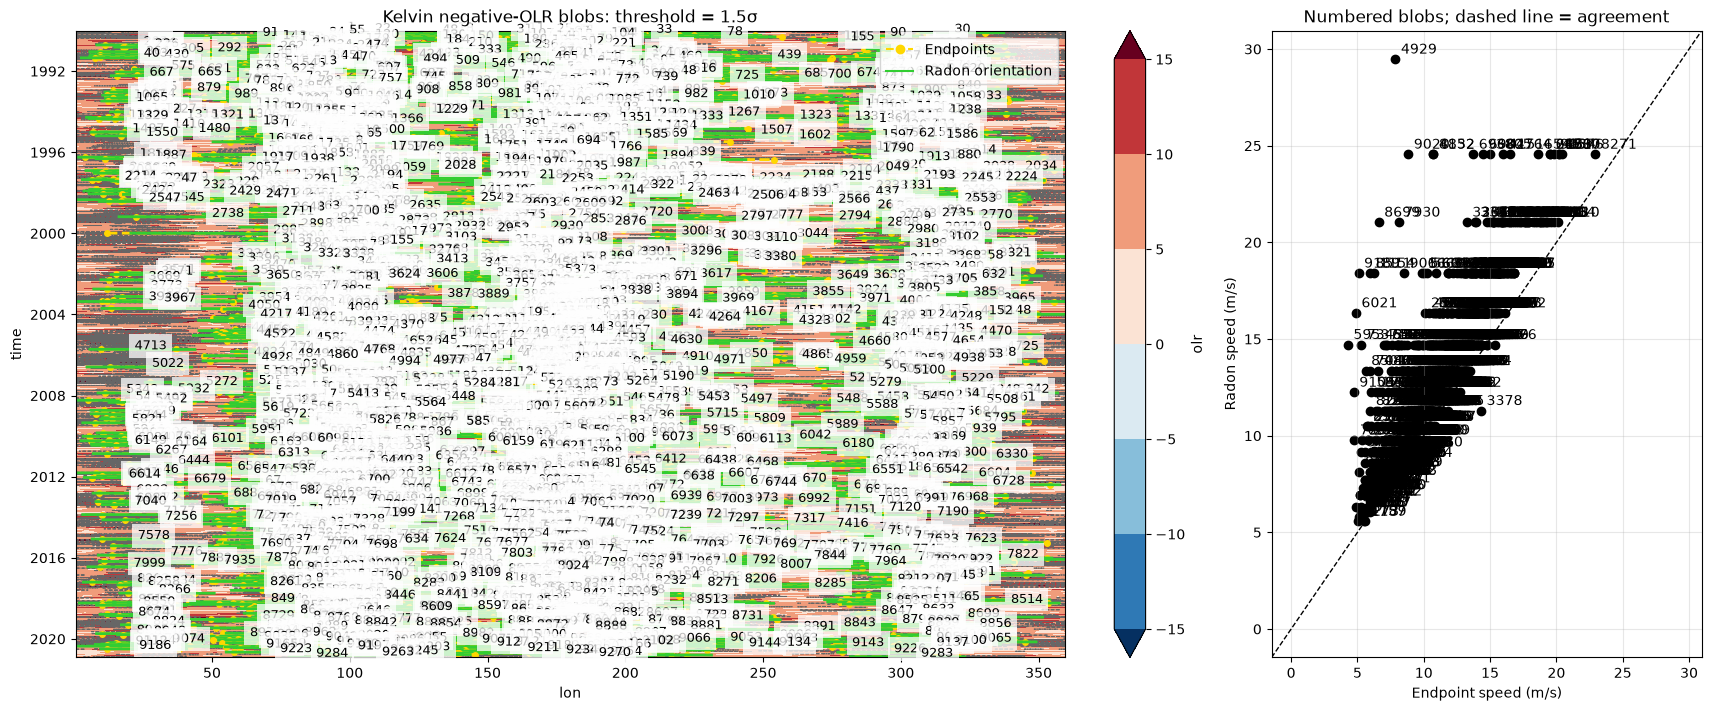

,event,duration_days,endpoint_m_s,radon_m_s
0,1,3.0,10.70,12.24
1,11,7.0,11.14,12.24
2,18,4.0,10.14,11.30
3,22,4.0,14.32,18.40
4,25,3.0,16.12,21.04
...,...,...,...,...
1797,9254,4.0,17.54,21.04
1798,9263,3.0,13.07,14.71
1799,9270,3.0,15.63,18.40
1800,9283,4.0,11.85,13.37


In [60]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import ndimage as ndi

kelvin_data = wave_filtered_data["Kelvin"]

# Adjustable event definition
threshold_sigma = 1.5
min_duration_days = 3.0
min_pixels = 8

north = kelvin_data.sel(lat=slice(0, 15))
full_hov = north.weighted(
    np.cos(np.deg2rad(north.lat))
).mean("lat")

# Use the full available record for the reference standard deviation
sigma = full_hov.std(("time", "lon")).compute().item()

hov = (
    full_hov.sel(time=slice("1990-01-01", "2020-12-01"))
    .sortby("time")
    .sortby("lon")
    .transpose("time", "lon")
    .compute()
)

q = hov.values
lon = hov.lon.values
dates = hov.time.values
days = (dates - dates[0]) / np.timedelta64(1, "D")

dx = np.median(np.diff(lon))
dt = np.median(np.diff(days))

if not (
    np.allclose(np.diff(lon), dx)
    and np.allclose(np.diff(days), dt)
):
    raise ValueError("Longitude and time must be regularly spaced.")

if not np.isfinite(q).all():
    raise ValueError("Handle missing values before running this comparison.")

# Detect eight-connected negative-OLR blobs
labels, _ = ndi.label(
    q < -threshold_sigma * sigma,
    structure=np.ones((3, 3)),
)

angles = np.arange(-89.5, 90.0, 0.5)
metres_per_degree = 2 * np.pi * 6_371_000 / 360

# Converts image slope [longitude pixels / time pixels] to equatorial m/s
grid_speed = dx * metres_per_degree / (dt * 86400)

fig, (ax, comparison_ax) = plt.subplots(
    1, 2,
    figsize=(17, 7),
    gridspec_kw={"width_ratios": [2.3, 1]},
    constrained_layout=True,
)

hov.plot.contourf(
    ax=ax, x="lon", y="time",
    cmap="RdBu_r", center=0, robust=True,
)
hov.plot.contour(
    ax=ax, x="lon", y="time",
    levels=[-threshold_sigma * sigma],
    colors="0.4", linewidths=0.7,
    add_colorbar=False,
)

records = []

for event_id, region in enumerate(ndi.find_objects(labels), start=1):
    if region is None:
        continue

    ts, xs = region
    mask = labels[region] == event_id
    duration = days[ts.stop - 1] - days[ts.start]

    # Skip small blobs and those truncated by the plotting-window boundaries
    if (
        mask.sum() < min_pixels
        or duration < min_duration_days
        or ts.start == 0
        or ts.stop == q.shape[0]
        or xs.start == 0
        or xs.stop == q.shape[1]
    ):
        continue

    # Positive weights measuring the strength of negative OLR anomalies
    weights = np.where(mask, -q[region], 0.0)
    event_lon = lon[xs]
    event_days = days[ts]

    # ---- Endpoint estimate ----
    x0 = np.average(event_lon, weights=weights[0])
    x1 = np.average(event_lon, weights=weights[-1])

    endpoint_speed = (
        (x1 - x0) / duration * metres_per_degree / 86400
    )

    # ---- Radon estimate: rotate, integrate along columns, score ----
    # Pad sufficiently to avoid clipping the blob during rotation
    size = int(np.ceil(np.hypot(*weights.shape))) + 4
    py = size - weights.shape[0]
    px = size - weights.shape[1]
    image = np.pad(
        weights,
        ((py // 2, py - py // 2), (px // 2, px - px // 2)),
    )

    scores = []
    for angle in angles:
        projection = ndi.rotate(
            image, -angle,
            reshape=False,
            order=1,
            prefilter=False,
            mode="constant",
            cval=0.0,
        ).sum(axis=0)

        scores.append(np.sum(projection**2))

    best_angle = angles[np.argmax(scores)]
    slope_pixels = np.tan(np.deg2rad(best_angle))
    radon_speed = slope_pixels * grid_speed

    # Anchor the displayed Radon orientation at the weighted blob centre
    xc = np.sum(weights * event_lon[None, :]) / weights.sum()
    tc = np.sum(weights * event_days[:, None]) / weights.sum()

    end_days = np.array([event_days[0], event_days[-1]])
    end_dates = dates[[ts.start, ts.stop - 1]]
    radon_lon = xc + slope_pixels * dx / dt * (end_days - tc)

    ax.plot(
        [x0, x1], end_dates,
        "o--", color="gold", lw=2, ms=4,
    )
    ax.plot(
        radon_lon, end_dates,
        color="limegreen", lw=2,
    )
    ax.text(
        xc, dates[(ts.start + ts.stop - 1) // 2],
        str(event_id),
        fontsize=9,
        bbox={"facecolor": "white", "alpha": 0.75, "edgecolor": "none"},
    )

    records.append({
        "event": event_id,
        "duration_days": duration,
        "endpoint_m_s": endpoint_speed,
        "radon_m_s": radon_speed,
    })

ax.plot([], [], "o--", color="gold", label="Endpoints")
ax.plot([], [], color="limegreen", label="Radon orientation")
ax.legend(loc="upper right")
ax.set_xlim(lon[0], lon[-1])
ax.invert_yaxis()
ax.set_title(f"Kelvin negative-OLR blobs: threshold = {threshold_sigma:g}σ")

speed_comparison = pd.DataFrame(records)

if speed_comparison.empty:
    comparison_ax.text(
        0.5, 0.5, "No complete blobs passed the settings",
        ha="center", transform=comparison_ax.transAxes,
    )
else:
    comparison_ax.scatter(
        speed_comparison.endpoint_m_s,
        speed_comparison.radon_m_s,
        color="black",
    )

    for row in records:
        comparison_ax.annotate(
            str(row["event"]),
            (row["endpoint_m_s"], row["radon_m_s"]),
            xytext=(4, 4), textcoords="offset points",
        )

    values = speed_comparison[["endpoint_m_s", "radon_m_s"]].to_numpy()
    lo = min(0.0, values.min())
    hi = max(0.0, values.max())
    margin = max(1.0, 0.05 * (hi - lo))
    limits = (lo - margin, hi + margin)

    comparison_ax.plot(limits, limits, "k--", lw=1)
    comparison_ax.set_xlim(limits)
    comparison_ax.set_ylim(limits)

comparison_ax.set(
    xlabel="Endpoint speed (m/s)",
    ylabel="Radon speed (m/s)",
    title="Numbered blobs; dashed line = agreement",
)
comparison_ax.grid(alpha=0.3)

plt.show()
speed_comparison.round(2)

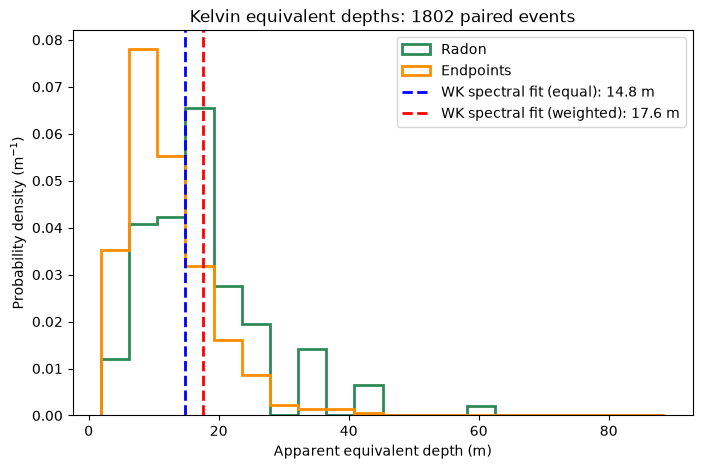

In [68]:
speeds = speed_comparison[["endpoint_m_s", "radon_m_s"]]
valid = np.isfinite(speeds).all(axis=1) & (speeds > 0).all(axis=1)

depths = (speeds.loc[valid] ** 2 / 9.81).rename(
    columns={"endpoint_m_s": "Endpoints", "radon_m_s": "Radon"}
)

# Shared bins for a direct comparison
bins = np.histogram_bin_edges(depths.to_numpy().ravel(), bins=20)

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(
    [depths["Endpoints"], depths["Radon"]],
    bins=bins,
    histtype="step",
    linewidth=2,
    label=["Endpoints", "Radon"],
    color=["darkorange", "seagreen"],
    density=True
)
ax.set(
    xlabel="Apparent equivalent depth (m)",
    ylabel="Number of events",
    title=f"Kelvin equivalent depths: {len(depths)} paired events",
)
ax.axvline(
    h_hat_equal,
    color="blue",
    linestyle="--",
    linewidth=2,
    label=f"WK spectral fit (equal): {h_hat_equal:.1f} m",
)

ax.axvline(
    h_hat_weighted,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"WK spectral fit (weighted): {h_hat_weighted:.1f} m",
)


ax.set_ylabel("Probability density (m$^{-1}$)")  # Because density=True
ax.legend()
plt.show()

In [ ]:
levels = [1.5, 2.0, 2.5]  # Exploratory envelope levels, relative to signal σ

for wave, data in wave_filtered_data.items():
    north = data.sel(lat=slice(0, 15))

    full_hovmoller = north.weighted(
        np.cos(np.deg2rad(north.lat))
    ).mean("lat")

    # Reference standard deviation from the full available record
    sigma = full_hovmoller.std(dim=("time", "lon")).compute().item()

    hovmoller = full_hovmoller.sel(
        time=slice("2011-10-15", "2011-11-15")
    ).compute()

    # Keep the full longitude circle for this operation
    analytic_signal = xr.apply_ufunc(
        hilbert,
        hovmoller,
        input_core_dims=[["lon"]],
        output_core_dims=[["lon"]],
        kwargs={"axis": -1},
    )

    envelope = np.abs(analytic_signal)
    envelope_sigma = envelope / sigma

    fig, ax = plt.subplots(figsize=(10, 6))

    hovmoller.plot.contourf(
        ax=ax,
        x="lon",
        y="time",
        cmap="RdBu_r",
        center=0,
        robust=True,
    )

    contours = envelope_sigma.plot.contour(
        ax=ax,
        x="lon",
        y="time",
        levels=levels,
        colors="black",
        linewidths=1,
        add_colorbar=False,
    )
    ax.clabel(
        contours,
        fmt=lambda value: f"{value:g}σ",
        fontsize=8,
    )

    ax.invert_yaxis()
    ax.set_title(f"{wave}: filtered anomalies and Hilbert envelope")
    plt.show()

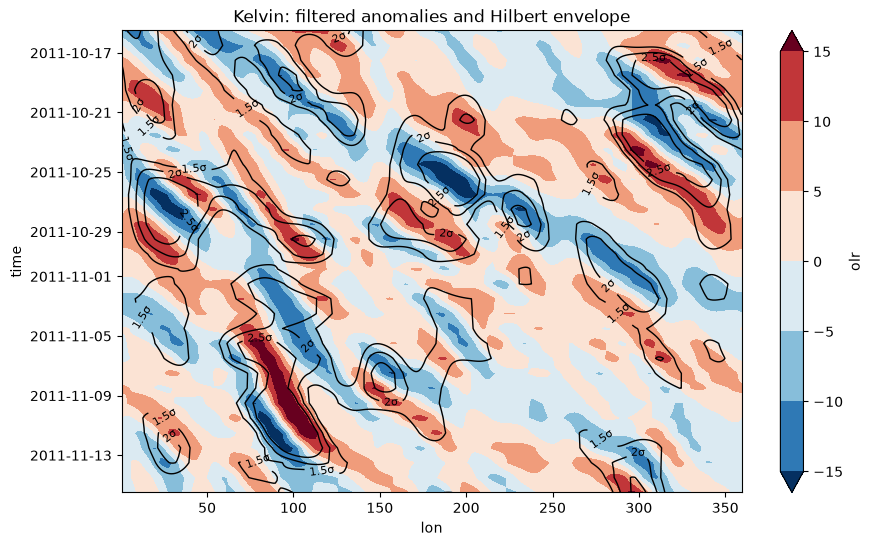

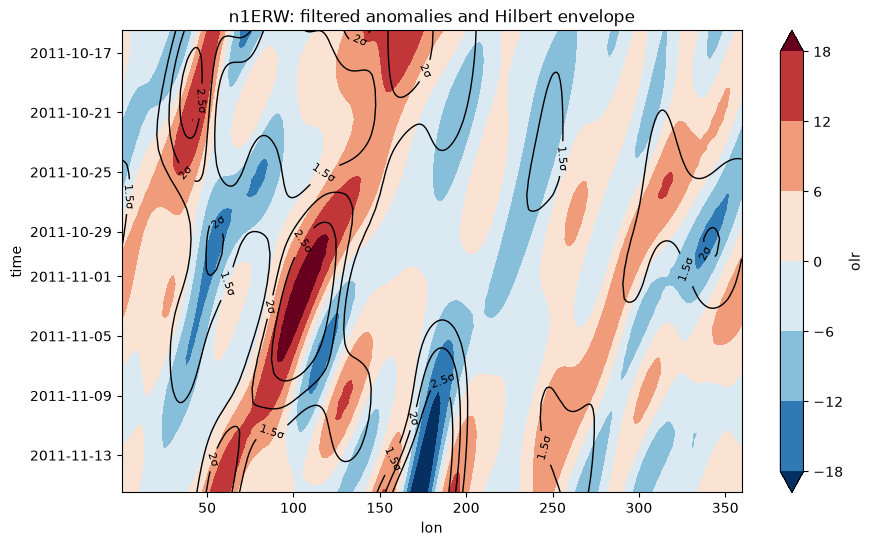

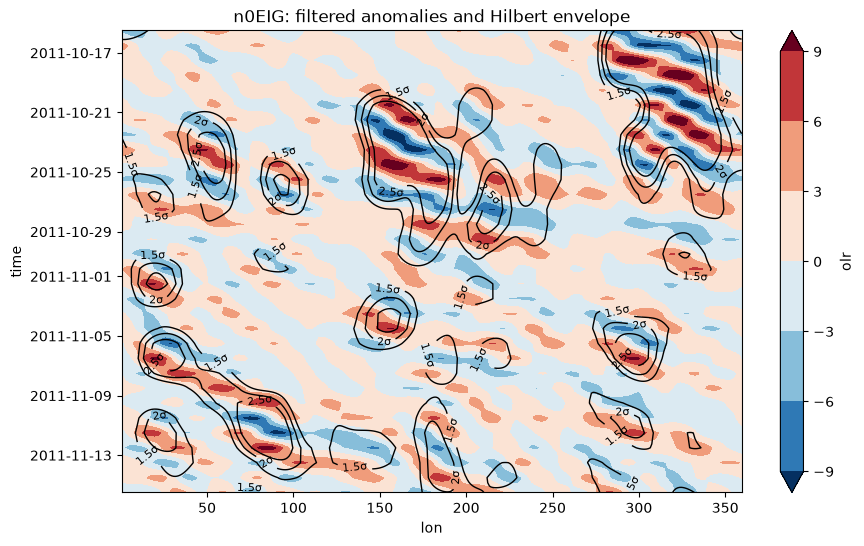

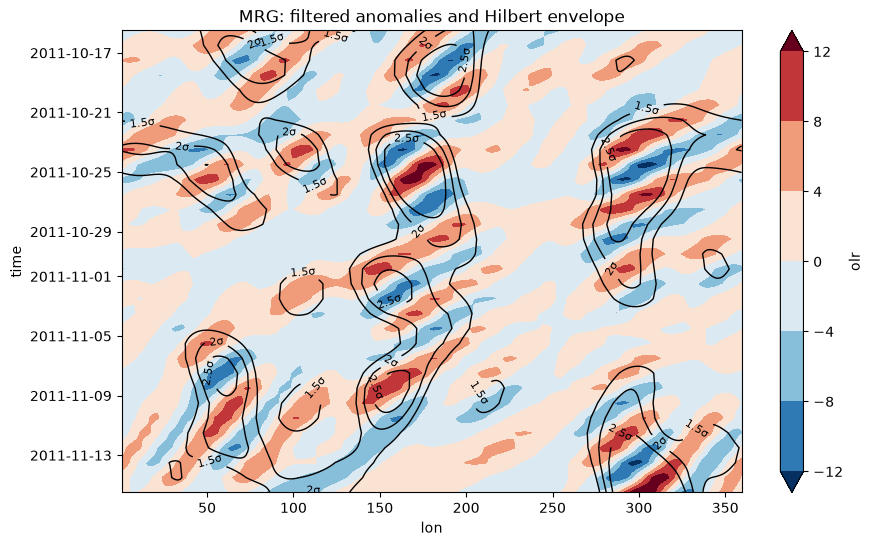

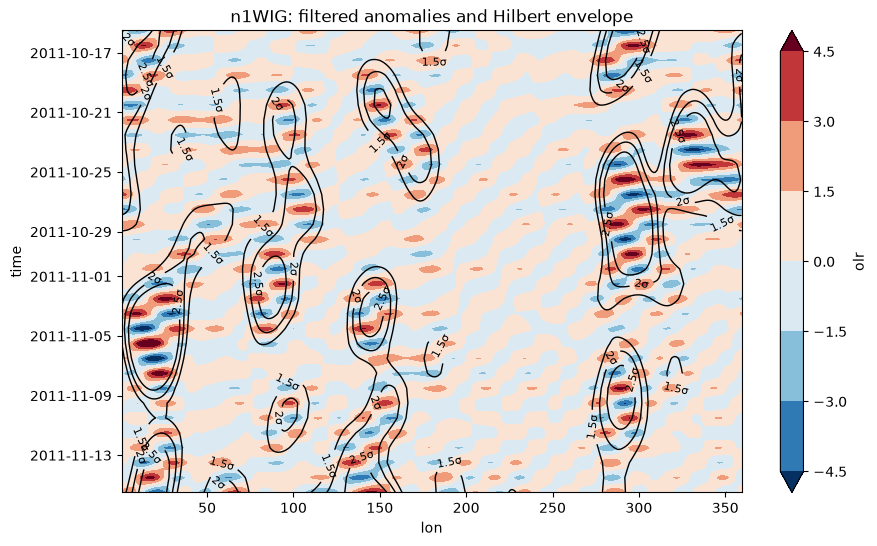

In [56]:
levels = [1.5, 2.0, 2.5]  # Exploratory envelope levels, relative to signal σ

for wave, data in wave_filtered_data.items():
    north = data.sel(lat=slice(0, 15))

    full_hovmoller = north.weighted(
        np.cos(np.deg2rad(north.lat))
    ).mean("lat")

    # Reference standard deviation from the full available record
    sigma = full_hovmoller.std(dim=("time", "lon")).compute().item()

    hovmoller = full_hovmoller.sel(
        time=slice("2011-10-15", "2011-11-15")
    ).compute()

    # Keep the full longitude circle for this operation
    analytic_signal = xr.apply_ufunc(
        hilbert,
        hovmoller,
        input_core_dims=[["lon"]],
        output_core_dims=[["lon"]],
        kwargs={"axis": -1},
    )

    envelope = np.abs(analytic_signal)
    envelope_sigma = envelope / sigma

    fig, ax = plt.subplots(figsize=(10, 6))

    hovmoller.plot.contourf(
        ax=ax,
        x="lon",
        y="time",
        cmap="RdBu_r",
        center=0,
        robust=True,
    )

    contours = envelope_sigma.plot.contour(
        ax=ax,
        x="lon",
        y="time",
        levels=levels,
        colors="black",
        linewidths=1,
        add_colorbar=False,
    )
    ax.clabel(
        contours,
        fmt=lambda value: f"{value:g}σ",
        fontsize=8,
    )

    ax.invert_yaxis()
    ax.set_title(f"{wave}: filtered anomalies and Hilbert envelope")
    plt.show()

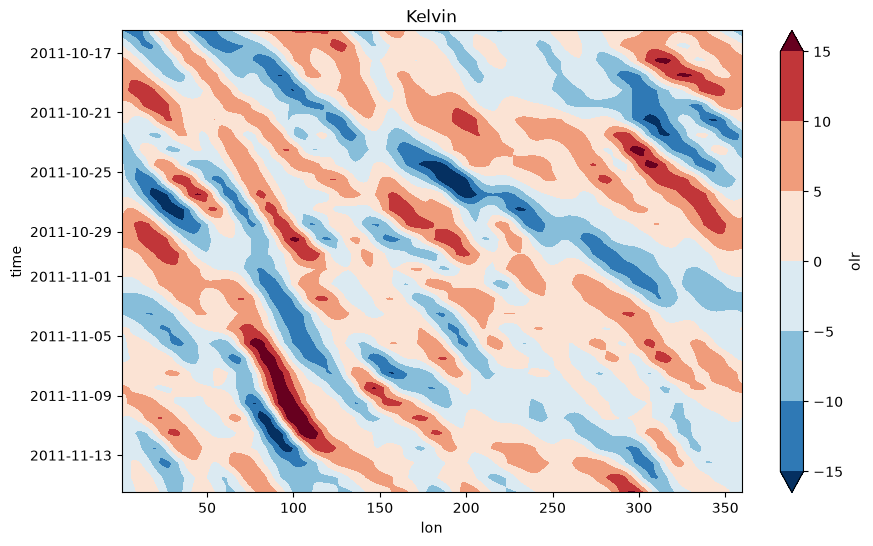

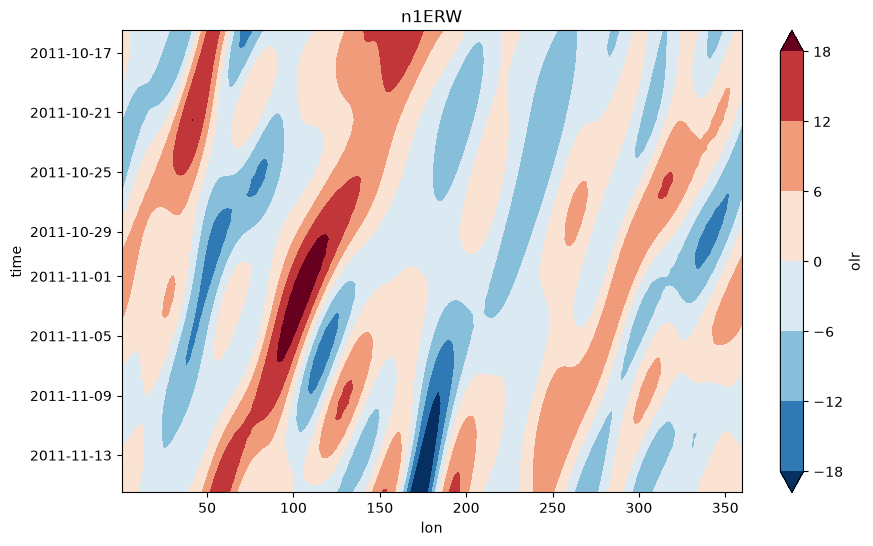

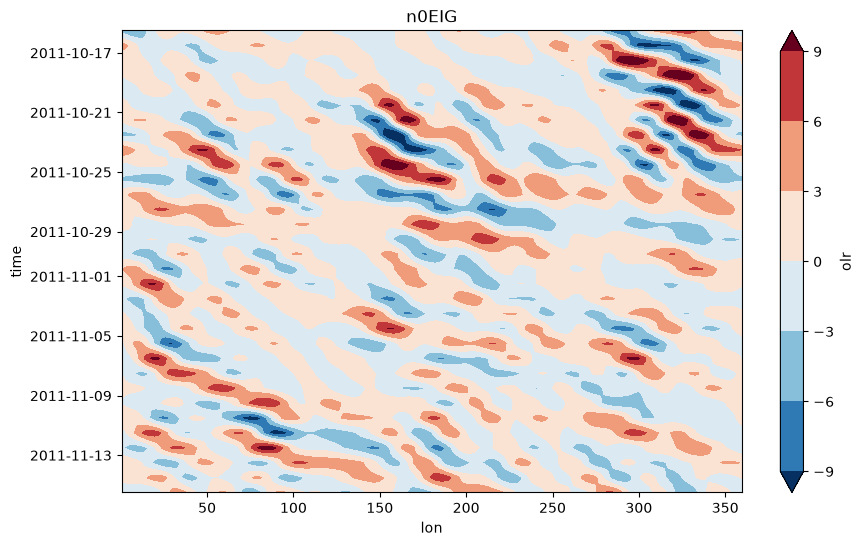

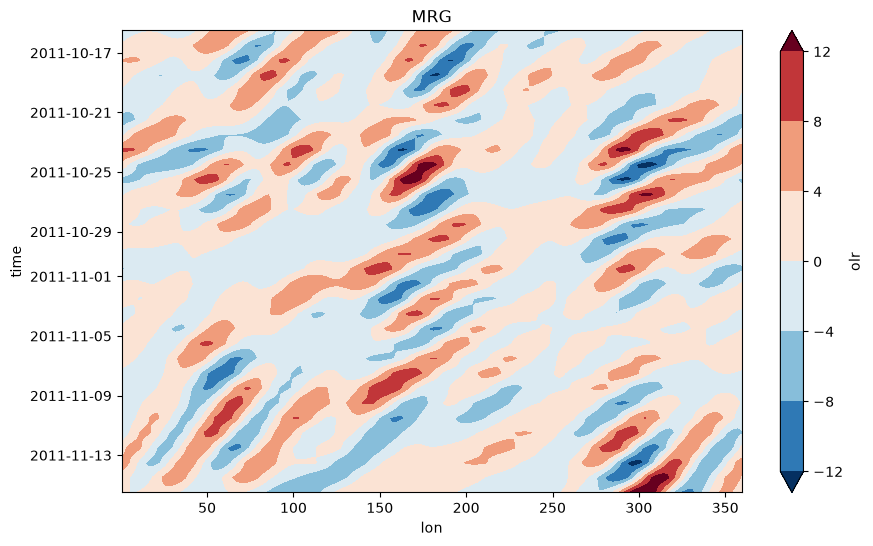

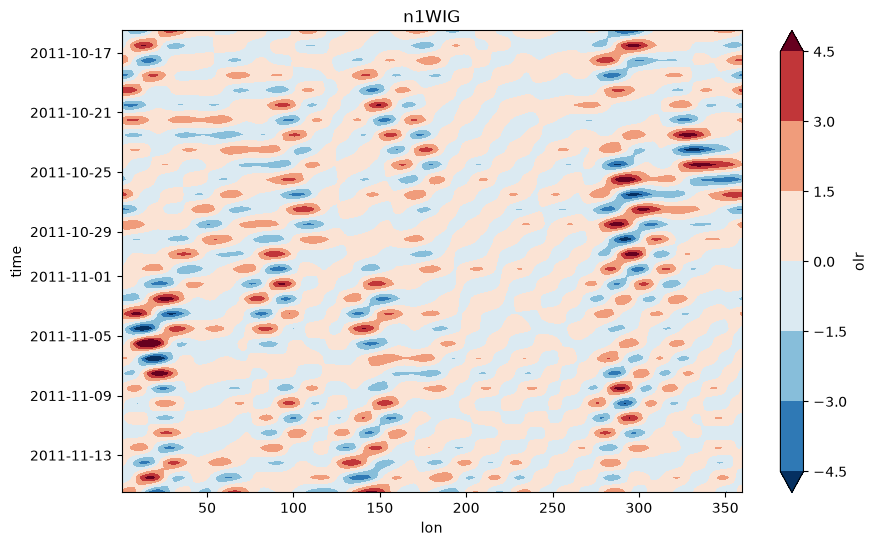

In [ ]:
for wave, data in wave_filtered_data.items():
    subset = data.sel(
        time=slice("2011-10-15", "2011-11-15"),
        lat=slice(0, 15),
    )

    hovmoller = subset.weighted(
        np.cos(np.deg2rad(subset.lat))
    ).mean("lat")

    

    fig, ax = plt.subplots(figsize=(10, 6))
    hovmoller.plot.contourf(
        ax=ax,
        x="lon",
        y="time",
        cmap="RdBu_r",
        center=0,
        robust=True,
    )
    ax.invert_yaxis()  # Time increases downward
    ax.set_title(wave)